# code_173 · A defined maintenance policy is different from a risk predictor

**Book:** section 33.1. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_33_GUIDE.md), [execution evidence](../CHAPTER_33_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_173).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Treatments, estimands, observed versus simulator-only outcomes, fitting roles and independent assessment are declared below. Generated interventions do not establish causal identification from arbitrary operational logs or validate an individual counterfactual.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=6473;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 6473


<a id="defined-treatment-and-target"></a>
 ## Name the action, population and outcome before estimating anything
 Treatment 1 means a specified inspection-plus-repair protocol before the year starts, not merely recording an inspection. Generate 20,000 independent buildings with a binary severity indicator and continuous load index. Baseline annual failure risk increases with both; treatment reduces risk by 0.02 in low-severity and 0.14 in high-severity buildings. Treatment is more likely for severe buildings(0.85 versus 0.15). A common latent uniform draw constructs paired potential outcomes for teaching audit; only the assigned outcome enters the observed record. A separate randomized assignment provides an actual experimental control on the same finite population. A two-year window assumes the annual risk rule persists and a shared pair of annual latent draws defines its potential outcomes. This is a declared structural assumption, not additional observed follow-up.


,quantity,risk_difference
0,Observed association,0.060251
1,Randomized difference,-0.080164
2,Finite population ATE,-0.077500
3,Treated population ATT,-0.119249
4,Selected population ATE,-0.113722
5,Two-year population ATE,-0.120250


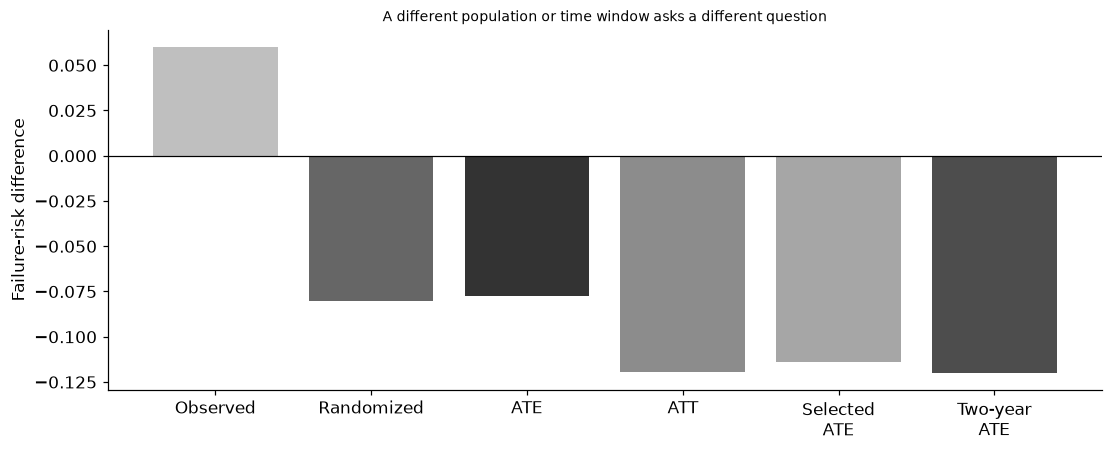

In [2]:
n=20000;severity=rng.integers(0,2,n);load=rng.uniform(0,1,n);p0=.03+.25*severity+.1*load;p1=p0-(.02+.12*severity);u=rng.random((n,2));Y0=(u[:,0]<p0).astype(int);Y1=(u[:,0]<p1).astype(int);A=(rng.random(n)<np.where(severity,.85,.15)).astype(int);observed=np.where(A,Y1,Y0);randomized=(rng.random(n)<.5).astype(int);random_observed=np.where(randomized,Y1,Y0)
def difference(y,a):return float(y[a==1].mean()-y[a==0].mean())
individual=Y1-Y0;two0=np.any(u<p0[:,None],axis=1).astype(int);two1=np.any(u<p1[:,None],axis=1).astype(int);selected=rng.random(n)<np.where(severity,.8,.2)
metrics={'Observed association':difference(observed,A),'Randomized difference':difference(random_observed,randomized),'Finite population ATE':float(individual.mean()),'Treated population ATT':float(individual[A==1].mean()),'Selected population ATE':float(individual[selected].mean()),'Two-year population ATE':float((two1-two0).mean())}
risk_by_assignment={str(a):float(observed[A==a].mean()) for a in [0,1]};assert np.array_equal(observed,np.where(A,Y1,Y0));assert np.all((p1>=0)&(p1<=p0)) and np.all(Y1<=Y0);assert len(observed)==n
RESULTS.update(buildings=n,treatment='specified inspection plus repair before year starts',outcome='failure within one year',observed_outcomes=n,hidden_alternative_outcomes=n,latent_potential_outcome_coupling='shared uniform; audit only',observational_treatment_probability_by_severity=[.15,.85],metrics=metrics,observational_group_risk=risk_by_assignment,selected_buildings=int(selected.sum()),selected_high_severity_fraction=float(severity[selected].mean()),true_mean_risk_ATE=float((p1-p0).mean()),true_mean_risk_ATT=float((p1[A==1]-p0[A==1]).mean()),two_year_assumption='same annual risk and declared two annual latent draws')
display(pd.DataFrame({'quantity':list(metrics),'risk_difference':list(metrics.values())}));fig,ax=plt.subplots(figsize=(10,4));labels=['Observed','Randomized','ATE','ATT','Selected\nATE','Two-year\nATE'];ax.bar(range(6),list(metrics.values()),color=['.75','.4','.2','.55','.65','.3']);ax.axhline(0,color='black',linewidth=.8);ax.set(xticks=range(6),xticklabels=labels,ylabel='Failure-risk difference',title='A different population or time window asks a different question');plt.show()


<a id="prediction-versus-intervention"></a>
 ## Cutting an assignment mechanism is an extra claim
 The observational graph has severityLcausing both assignmentAand failureY, with an additional treatment effect A→Y. Under do(A=1), assignment's incoming arrow is cut while the severity-to-outcome path persists. An accurate group-risk prediction P(Y|A)describes the observed assignment process; it does not average over the intervention population automatically. The small records panel shows only each unit's assigned potential outcome. The unobserved alternative stays marked?even though the simulator can audit both. Selection into the inspected dataset changes its severity distribution and hence its average effect; that selected estimand is not silently called the original population ATE.


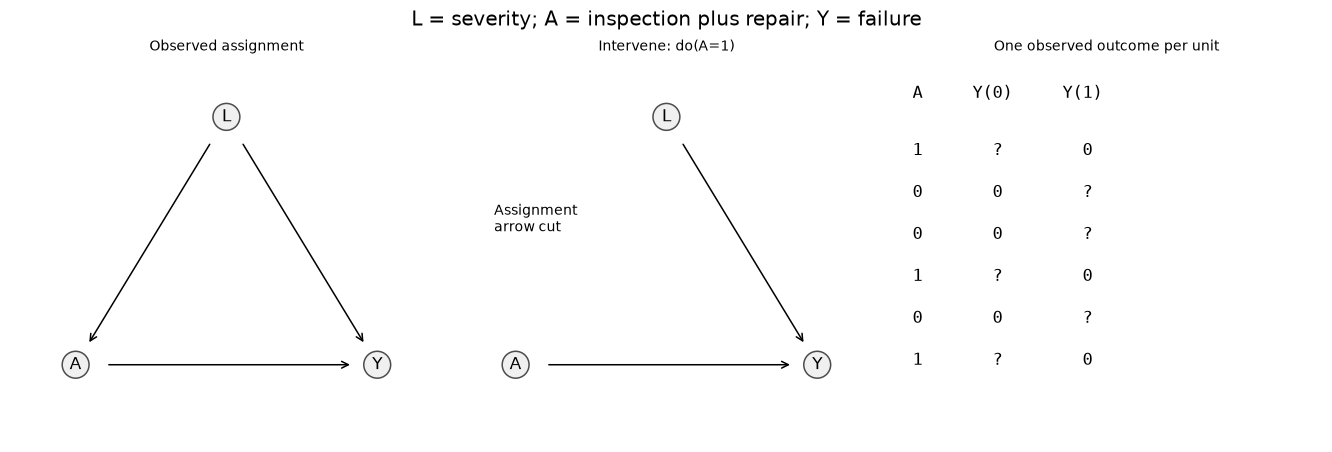

In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,4))
for j,title in enumerate(['Observed assignment','Intervene: do(A=1)']):
    ax=axes[j];ax.axis('off');pos={'L':(.5,.85),'A':(.15,.2),'Y':(.85,.2)}
    for node,(x,y) in pos.items():ax.text(x,y,node,ha='center',va='center',bbox={'boxstyle':'circle','facecolor':'.94','edgecolor':'.3'},transform=ax.transAxes)
    for start,end in [('L','Y'),('A','Y')]+([('L','A')] if j==0 else []):
        a=np.array(pos[start]);b=np.array(pos[end]);delta=b-a;ax.annotate('',xy=b-.08*delta,xytext=a+.1*delta,xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
    if j==1:ax.text(.1,.55,'Assignment\narrow cut',fontsize=9,transform=ax.transAxes)
    ax.set_title(title)
axes[2].axis('off');axes[2].text(.05,.9,'A     Y(0)     Y(1)',family='monospace',transform=axes[2].transAxes)
for i in range(6):
    left=str(observed[i]) if A[i]==0 else '?';right=str(observed[i]) if A[i]==1 else '?';axes[2].text(.05,.75-i*.11,f'{A[i]}       {left}        {right}',family='monospace',transform=axes[2].transAxes)
axes[2].set_title('One observed outcome per unit');fig.suptitle('L = severity; A = inspection plus repair; Y = failure');plt.show()
assert metrics['Finite population ATE']==float((Y1-Y0).mean()) and selected.sum()<n


In [4]:
summary={'example_id':'code_173','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['explicit potential outcomes for a defined inspection plus repair policy', 'observational assignment randomized assignment and simulator-only audit truth', 'ATE ATT target-population and time-window distinctions', 'selection changes the target estimand', 'intervention graph cuts assignment rather than predicting a group risk'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["explicit potential outcomes for a defined inspection plus repair policy", "observational assignment randomized assignment and simulator-only audit truth", "ATE ATT target-population and time-window distinctions", "selection changes the target estimand", "intervention graph cuts assignment rather than predicting a group risk"], "elapsed_seconds": 0.453, "example_id": "code_173", "hardware": "Darwin arm64 CPU", "results": {"buildings": 20000, "hidden_alternative_outcomes": 20000, "latent_potential_outcome_coupling": "shared uniform; audit only", "metrics": {"Finite population ATE": -0.0775, "Observed association": 0.0602513749190933, "Randomized difference": -0.0801641546151631, "Selected population ATE": -0.11372236606253734, "Treated population ATT": -0.11924854329917621, "Two-year population ATE": -0.12025}, "observational_group_risk": {"0": 0.11676289070276727, "1": 0.17701426562186057}, "observational_treatment_probability_by_severi